### 06 · Extremos en modo hindcast: máximos anuales (1985–2025)
f histórica (OOF 1985–2015 + test 2016–2025, del 04) + ruido TAR con mapeo por decil × mes (05), 50 realizaciones (`outputs/ruido/hs_hindcast_{point}.pkl`). Cada realización da 41 máximos anuales que se comparan con los observados. Las simulaciones se recortan a las horas con observación, para que los huecos de CMEMS afecten igual a los dos.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import genextreme

os.makedirs("figuras", exist_ok=True)
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.spines.top": False, "axes.spines.right": False,
})

In [2]:
point = "p102"
hs_sims = pd.read_pickle(f"outputs/ruido/hs_hindcast_{point}.pkl")              # (horas, realizaciones)
hs_all = pd.read_csv(f"inputs/waves_bulk_{point}.csv", index_col=0, parse_dates=True)["VHM0"].loc["1985":"2025"]
hs_all = hs_all.reindex(hs_sims.index)
hs_sims = hs_sims.where(hs_all.notna(), axis=0)                                    # mismas horas que el observado
print(hs_sims.shape, f"{hs_all.notna().mean():.1%} de horas con observación")

(359400, 50) 100.0% de horas con observación


años con el máximo observado dentro del 95 % simulado: 90%  (esperado ≈ 95 %)
por encima: 2% | por debajo: 7%
media máx. anual: obs 5.66 | sim 5.76 [5.64–5.87]
corr año a año (obs vs mediana sim): 0.55


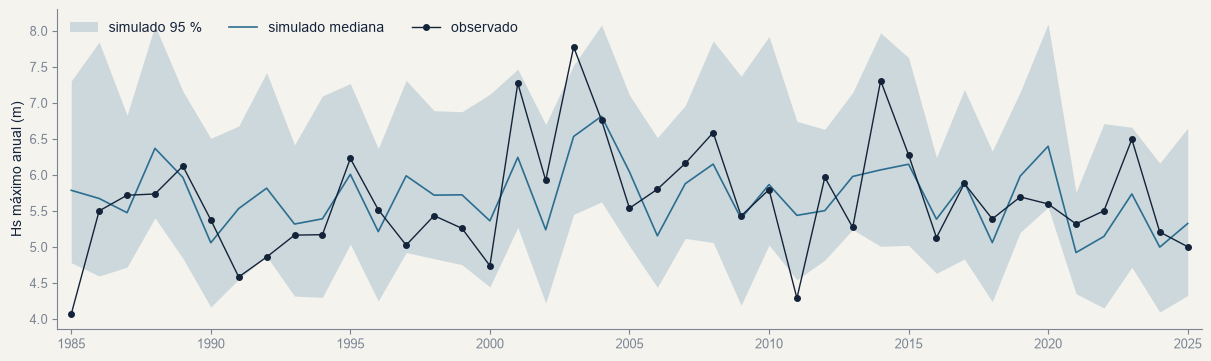

In [3]:
#### Máximos anuales
am_obs = hs_all.groupby(hs_all.index.year).max()
am_sim = hs_sims.groupby(hs_sims.index.year).max()            # (41 años, n_sims)
lo, med, hi = am_sim.quantile(0.025, axis=1), am_sim.median(axis=1), am_sim.quantile(0.975, axis=1)

dentro = ((am_obs >= lo) & (am_obs <= hi)).mean()
print(f"años con el máximo observado dentro del 95 % simulado: {dentro:.0%}  (esperado ≈ 95 %)")
print(f"por encima: {(am_obs > hi).mean():.0%} | por debajo: {(am_obs < lo).mean():.0%}")
print(f"media máx. anual: obs {am_obs.mean():.2f} | sim {am_sim.mean().median():.2f} [{am_sim.mean().quantile(0.025):.2f}–{am_sim.mean().quantile(0.975):.2f}]")
print(f"corr año a año (obs vs mediana sim): {am_obs.corr(med):.2f}")

fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.fill_between(am_sim.index, lo, hi, color=AZUL, alpha=0.2, lw=0, label="simulado 95 %")
ax.plot(med, color=AZUL, lw=1.2, label="simulado mediana")
ax.plot(am_obs, "o-", color=TINTA, ms=4, lw=1, label="observado")
ax.set(ylabel="Hs máximo anual (m)", xlim=(am_obs.index[0] - 0.5, am_obs.index[-1] + 0.5))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left", ncol=3)
fig.savefig("figuras/extremos_maximos_anuales.png", dpi=200)
plt.show()

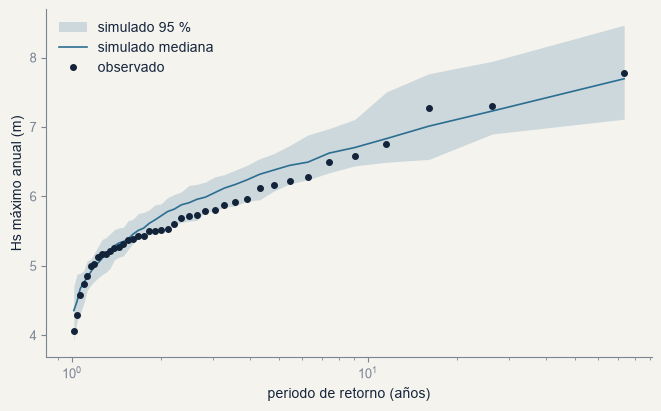

In [4]:
#### Curva de periodos de retorno empírica (Gringorten): obs vs banda de las simulaciones
n = len(am_obs)
T = 1 / (1 - (np.arange(1, n + 1) - 0.44) / (n + 0.12))           # periodo de retorno de cada orden
am_sim_ord = np.sort(am_sim.values, axis=0)                       # (n, n_sims), cada simulación ordenada

fig, ax = plt.subplots(figsize=(6.5, 4), constrained_layout=True)
ax.fill_between(T, np.percentile(am_sim_ord, 2.5, axis=1), np.percentile(am_sim_ord, 97.5, axis=1),
                color=AZUL, alpha=0.2, lw=0, label="simulado 95 %")
ax.plot(T, np.median(am_sim_ord, axis=1), color=AZUL, lw=1.2, label="simulado mediana")
ax.plot(T, np.sort(am_obs.values), "o", color=TINTA, ms=4, label="observado")
ax.set(xscale="log", xlabel="periodo de retorno (años)", ylabel="Hs máximo anual (m)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
fig.savefig("figuras/extremos_gringorten.png", dpi=200)
plt.show()

In [5]:
#### GEV: parámetros y niveles de retorno, obs vs simulaciones
T_ret = np.array([2, 10, 50, 100])

def gev(am):
    c_, loc, scale = genextreme.fit(am)
    return {"ξ": -c_, "μ": loc, "σ": scale, **{f"Hs{t}": genextreme.ppf(1 - 1 / t, c_, loc, scale) for t in T_ret}}

g_obs = pd.Series(gev(am_obs.values))
g_sim = pd.DataFrame([gev(am_sim[c_].values) for c_ in am_sim.columns])
tabla_gev = pd.DataFrame({"obs": g_obs, "sim med": g_sim.median(), "sim lo": g_sim.quantile(0.025), "sim hi": g_sim.quantile(0.975)})
print(tabla_gev.round(2).to_string())
print("ojo: con 41 años, ξ y Hs100 tienen mucha incertidumbre también en lo observado")

        obs  sim med  sim lo  sim hi
ξ     -0.13    -0.16   -0.38    0.08
μ      5.34     5.45    5.28    5.60
σ      0.68     0.70    0.54    0.85
Hs2    5.59     5.70    5.50    5.84
Hs10   6.67     6.74    6.50    7.03
Hs50   7.43     7.48    7.06    8.07
Hs100  7.70     7.76    7.16    8.60
ojo: con 41 años, ξ y Hs100 tienen mucha incertidumbre también en lo observado


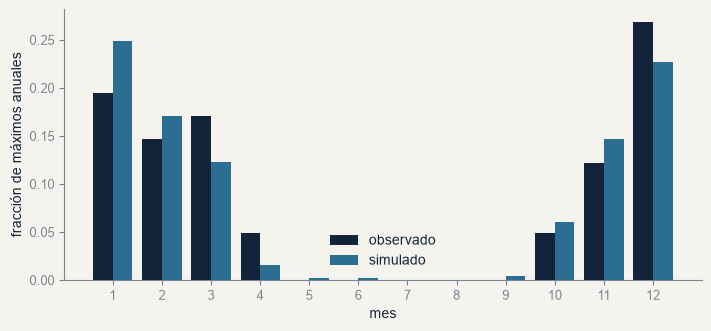

In [6]:
#### ¿En qué mes cae el máximo anual?
mes_obs = hs_all.groupby(hs_all.index.year).idxmax().dt.month
mes_sim = pd.concat([hs_sims[c_].groupby(hs_sims.index.year).idxmax().dt.month for c_ in hs_sims.columns])
frec = pd.DataFrame({"obs": mes_obs.value_counts(normalize=True), "sim": mes_sim.value_counts(normalize=True)}).reindex(range(1, 13)).fillna(0)

fig, ax = plt.subplots(figsize=(7, 3.2), constrained_layout=True)
ax.bar(frec.index - 0.2, frec["obs"], width=0.4, color=TINTA, label="observado")
ax.bar(frec.index + 0.2, frec["sim"], width=0.4, color=AZUL, label="simulado")
ax.set(xticks=range(1, 13), xlabel="mes", ylabel="fracción de máximos anuales")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.savefig("figuras/extremos_mes_maximo.png", dpi=200)
plt.show()